## Train SRU model with embeddings-resnet50-100

Hope it will work...

### Installing SRU with v3.0.0

In [1]:
!pip install sru==3.0.0.dev6

### Importing Necessary Libraries

In [2]:
import logging
import os

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sru import SRUpp
from torch.nn import CrossEntropyLoss
from torch.nn import Module, Dropout, Linear
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import gc

### Set the Device to CUDA

In [3]:
# Set the device to use (e.g., 'cpu', 'cuda', 'mps')
device = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))

# Select Device According to Availability
print("Device selected:", device)

# If the device is CUDA, print the device capability
if device.type == "cuda":
    os.system("nvidia-smi")
    print()
    print("Device type:", device.type)
    print("Capability:", torch.cuda.get_device_capability(device))
else:
    print("Device capabilities are limited on MPSs and CPUs.")

Device selected: cuda
Fri Mar 29 13:06:41 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.129.03             Driver Version: 535.129.03   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla P100-PCIE-16GB           Off | 00000000:00:04.0 Off |                    0 |
| N/A   35C    P0              25W / 250W |      2MiB / 16384MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+---

In [4]:
### Read the file, Validate and View Shape

In [5]:
embedding_file = np.load('/kaggle/input/multiclass-custom-resnet-embedding/multiclass_train_embeddings.npy')
label_file = np.load('/kaggle/input/multiclass-custom-resnet-embedding/multiclass_train_labels.npy')

gc.collect()

62

In [6]:
inference_sample_size = 0.05
test_sample_size = 0.2

In [7]:
# Inference split
embedding, inference_sample_embedding, labels, inference_sample_label = train_test_split(
    embedding_file, label_file, test_size=inference_sample_size, random_state=42
)

# Train Test Split
x_train, x_test, y_train, y_test = train_test_split(
    embedding, labels, test_size=test_sample_size, random_state=42
)

In [8]:
train_embeddings = torch.from_numpy(x_train).to(device)
train_labels = torch.from_numpy(y_train).to(device)
test_embeddings = torch.from_numpy(x_test).to(device)
test_labels = torch.from_numpy(y_test).to(device)
inference_embeddings = torch.from_numpy(inference_sample_embedding).to(device)
inference_labels = torch.from_numpy(inference_sample_label).to(device)

In [9]:
# Delete initial file variables
del embedding_file
del label_file

# Delete 2nd order variables (splitting)
del embedding
del labels
del inference_sample_embedding
del inference_sample_label
del x_train
del x_test
del y_train
del y_test

In [10]:
print(train_embeddings.shape)
print(train_labels.shape)
print(test_embeddings.shape)
print(test_labels.shape)
print(inference_embeddings.shape)
print(inference_labels.shape)

torch.Size([5320, 150, 1024])
torch.Size([5320])
torch.Size([1330, 150, 1024])
torch.Size([1330])
torch.Size([350, 150, 1024])
torch.Size([350])


In [11]:
print(inference_labels)

tensor([ 0,  7,  9,  0,  0,  9,  0,  0, 11,  0,  6,  2,  8,  0,  0, 10,  0,  5,
        10,  0,  8,  5,  0,  5,  6,  7,  0,  5,  0,  7,  0,  3,  0, 11,  5,  5,
         4,  6,  0,  0,  0,  0,  0,  0,  0,  0,  5,  0,  8,  7, 10,  0,  0,  5,
         0,  8,  5,  0, 10,  0,  5,  5,  0,  0,  0, 11,  7,  0, 11,  0,  0,  0,
         0,  8,  0,  3, 11,  5,  7,  5,  0,  0,  0,  0,  0,  0,  0,  0,  7,  6,
         8,  8,  0,  0,  8,  3,  4,  0,  5,  0, 11,  0,  0,  2, 10,  4,  5,  8,
         0,  0,  0,  0,  3,  0,  8,  7,  0,  7,  9,  0,  7,  5,  5,  5,  5,  4,
         0,  0,  0,  0,  1, 10,  0,  2,  0,  0,  7,  0,  0,  0,  6,  0,  4, 11,
         0,  0,  0,  8,  7,  0,  0,  0,  3,  0,  9, 10,  0,  5,  9,  5,  0, 10,
         0,  0,  5, 10,  5,  0, 11,  8,  0,  8,  0,  8,  0,  0,  0,  5,  0,  4,
        11,  0,  4, 11,  0, 10,  0,  0,  9,  2,  9,  0,  0,  8,  5,  4,  7,  0,
         0,  1,  0,  0,  0,  0,  0, 11,  4,  2,  9,  0,  8,  0,  7, 10,  9, 10,
         2, 10,  8,  8,  2,  0,  8,  5, 

In [12]:
batch_size = 8

# Create TensorDataset
train_data = TensorDataset(train_embeddings, train_labels)
test_data = TensorDataset(test_embeddings, test_labels)
inference_data = TensorDataset(inference_embeddings, inference_labels)

train_loader = DataLoader(train_data, shuffle=True, batch_size=batch_size)
test_loader = DataLoader(test_data, shuffle=True, batch_size=batch_size)
inference_loader = DataLoader(inference_data, shuffle=True, batch_size=batch_size)

### Train Test Split, Convert to torch.tensor and View Shape

In [13]:
class SRUppModel(Module):
    def __init__(self, input_size, hidden_size):
        super(SRUppModel, self).__init__()
        # Main SRU layer
        self.sru_layers = SRUpp(
            input_size=input_size,
            hidden_size=hidden_size,
        
            num_heads=8,
            proj_size = 1024,
            num_layers=2,
            dropout=0.0,
            layer_norm=True,
            highway_bias=0.0,
            rescale=True,
            proj_input_to_hidden_first=False,
            normalize_after=False,
        ).to(device)
        
        # Dropout layer
        self.dropout = Dropout(0.2).to(device)
        
        # Linear layer (Fully connected layer)
        self.linear = Linear(hidden_size, out_features=12).to(device)
        
        # L2 regularization
        self.l2_reg_lambda = 1e-5

    def forward(self, x):
        output_states, _, _ = self.sru_layers(x)
        output = self.linear(self.dropout(output_states[-1]))
        return output

    def l2_regularization(self):
        l2_reg = torch.tensor(0., device=device)
        for param in self.parameters():
            l2_reg += torch.norm(param, p=2)
        return self.l2_reg_lambda * l2_reg


model = SRUppModel(1024, 1024)
model = model.to(device)
model

SRUppModel(
  (sru_layers): SRUpp(
    (rnn_lst): ModuleList(
      (0-1): 2 x SRUppCell(1024, 1024, rescale=True, layer_norm=True, normalize_after=False,
        transform_module=SRUppAttention(
        (dropout): Dropout(p=0.0, inplace=False)
        (linear1): Linear(in_features=1024, out_features=1024, bias=False)
        (linear2): Linear(in_features=1024, out_features=2048, bias=False)
        (linear3): Linear(in_features=1024, out_features=3072, bias=False)
        (layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      )
      )
    )
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (linear): Linear(in_features=1024, out_features=12, bias=True)
)

In [14]:
# Define your loss function and optimizer
criterion = CrossEntropyLoss()
optimizer = Adam(model.parameters())

In [15]:
model.train()
epochs = 100

total_correct_all_epochs = 0
total_samples_all_epochs = 0

# Setup logging
logging.basicConfig(filename='training.log', level=logging.INFO)

for epoch in range(epochs):
    total_correct = 0
    total_samples = 0
    total_loss = 0.0

    # Create tqdm progress bar for training loader
    progress_bar = tqdm(enumerate(train_loader), desc=f"Epoch {epoch + 1}/{epochs}", total=len(train_loader))

    for i, (videos, labels) in progress_bar:
        videos = videos.permute(1, 0, 2)
        # Forward pass
        # (100, 8, 2048)
        outputs = model(videos)
        labels = labels.long()  # Convert labels to Long type
        loss = criterion(outputs, labels) + model.l2_regularization()  # calculates loss
        total_loss += loss.item()
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Calculate accuracy per batch
        _, predicted = torch.max(outputs.data, 1)
        total_samples += labels.size(0)
        total_correct += (predicted == labels).sum().item()
        batch_accuracy = 100 * total_correct / total_samples

        # Update progress bar
        progress_bar.set_postfix(loss=loss.item(), accuracy=batch_accuracy)
        
        # Update overall accuracy counters
        total_correct_all_epochs += total_correct
        total_samples_all_epochs += total_samples

    # Log epoch statistics
    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = 100 * total_correct / total_samples
    logging.info(f'Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss}, Accuracy: {epoch_accuracy}%')

    print(f'Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss}, Accuracy: {epoch_accuracy}%')

# Close logging
logging.shutdown()

overall_accuracy = 100 * total_correct_all_epochs / total_samples_all_epochs
print(f'Average Train Accuracy of the model on the train videos: {overall_accuracy}%')

Epoch 1/100: 100%|██████████| 665/665 [00:17<00:00, 37.72it/s, accuracy=56.3, loss=0.776]


Epoch [1/100], Loss: 1.4826272692223241, Accuracy: 56.296992481203006%


Epoch 2/100: 100%|██████████| 665/665 [00:16<00:00, 39.91it/s, accuracy=67, loss=1.11]


Epoch [2/100], Loss: 1.0555193084971348, Accuracy: 67.01127819548873%


Epoch 3/100: 100%|██████████| 665/665 [00:16<00:00, 39.75it/s, accuracy=72.1, loss=0.338]


...

Epoch [98/100], Loss: 0.06283777749263926, Accuracy: 98.83458646616542%


Epoch 99/100: 100%|██████████| 665/665 [00:16<00:00, 39.43it/s, accuracy=98.3, loss=0.00941]


Epoch [99/100], Loss: 0.09711536559367315, Accuracy: 98.28947368421052%


Epoch 100/100: 100%|██████████| 665/665 [00:16<00:00, 39.80it/s, accuracy=98.6, loss=0.00937]


Epoch [100/100], Loss: 0.09982938323926209, Accuracy: 98.59022556390977%
Average Train Accuracy of the model on the train videos: 95.69155546523967%


In [16]:
# del model

In [17]:
model.eval()

with torch.no_grad():
    correct = 0
    total = 0
    for videos, labels in test_loader:
        videos = videos.permute(1, 0, 2)
        outputs = model(videos)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        #print test accuracy per test

    print(f'Test Accuracy of the model on the test videos: {100 * correct / total}%')

Test Accuracy of the model on the test videos: 93.38345864661655%


Confusion Matrix:
[[663   0   1   1   4   5   0   0   2   0   0   0]
 [  0  33   1   0   0   0   0   0   0   0   0   0]
 [  1   0  33   1   0   2   1   0   0   0   0   0]
 [  1   1   0  41   0   0   0   0   0   0   0   0]
 [ 13   0   3   0  53   0   0   0   1   1   0   0]
 [  6   0   1   0   0  93   0   1   0   0   0   1]
 [  5   0   0   1   2   1  13   0   0   0   0   0]
 [  5   0   0   1   1   0   0  85   0   0   2   0]
 [  1   0   0   2   1   0   0   1  74   0   0   0]
 [  4   1   1   0   1   1   0   1   0  35   0   0]
 [  0   0   1   1   0   0   0   0   0   0  70   0]
 [  2   1   1   0   0   0   0   2   0   0   0  49]]


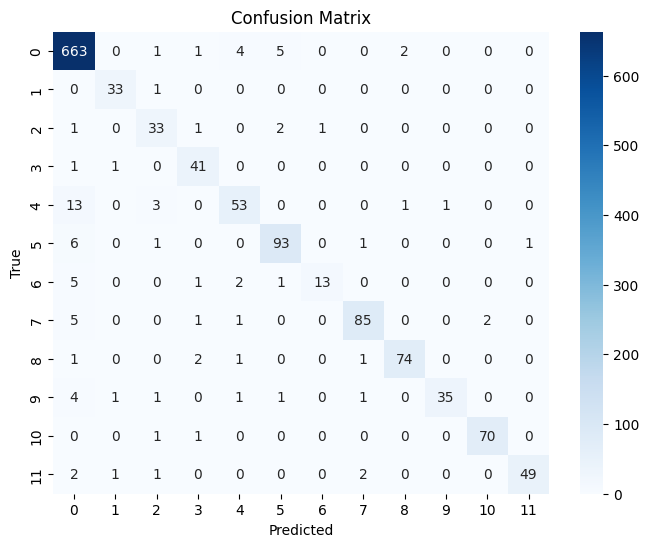

In [18]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Set model to evaluation mode
model.eval()

# Initialize variables for predictions and ground truth labels
all_predictions = []
all_labels = []

# Iterate through the test dataset
for videos, labels in test_loader:
#     videos = videos.unsqueeze(0)
    videos = videos.permute(1, 0, 2)
    # Forward pass
    outputs = model(videos)
    # Predictions
    _, predicted = torch.max(outputs.data, 1)
    # Append predictions and labels to the lists
    all_predictions.extend(predicted.tolist())
    all_labels.extend(labels.tolist())

# Convert predictions and labels lists to numpy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

# Generate confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(conf_matrix)

import matplotlib.pyplot as plt
import seaborn as sns

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [19]:
# from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
# import matplotlib.pyplot as plt

# # Set model to evaluation mode
# model.eval()

# # Initialize variables for predictions and ground truth labels
# all_probs = []
# all_labels = []

# # Iterate through the test dataset
# for videos, labels in test_loader:
# #     videos = videos.unsqueeze(0)
#     videos = videos.permute(1, 0, 2)
#     # Forward pass
#     outputs = model(videos)
#     # Get probabilities
#     probs = torch.softmax(outputs, dim=1)[:, 1].detach().cpu().numpy()
#     # Append probabilities and labels to the lists
#     all_probs.extend(probs.tolist())
#     all_labels.extend(labels.tolist())

# # Convert probabilities and labels lists to numpy arrays
# all_probs = np.array(all_probs)
# all_labels = np.array(all_labels)

# # AUC ROC Curve
# fpr, tpr, _ = roc_curve(all_labels, all_probs)
# roc_auc = auc(fpr, tpr)

# plt.figure()
# plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
# plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle=':')
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('Receiver Operating Characteristic (ROC) Curve')
# plt.legend(loc="lower right")
# plt.show()

# # Precision-Recall Curve
# precision, recall, _ = precision_recall_curve(all_labels, all_probs)
# average_precision = average_precision_score(all_labels, all_probs)

# plt.figure()
# plt.step(recall, precision, color='b', alpha=0.2, where='post')
# plt.fill_between(recall, precision, step='post', alpha=0.2, color='b')
# plt.xlabel('Recall')
# plt.ylabel('Precision')
# plt.ylim([0.0, 1.05])
# plt.xlim([0.0, 1.0])
# plt.title('Precision-Recall Curve (AP={0:0.2f})'.format(average_precision))
# plt.show()

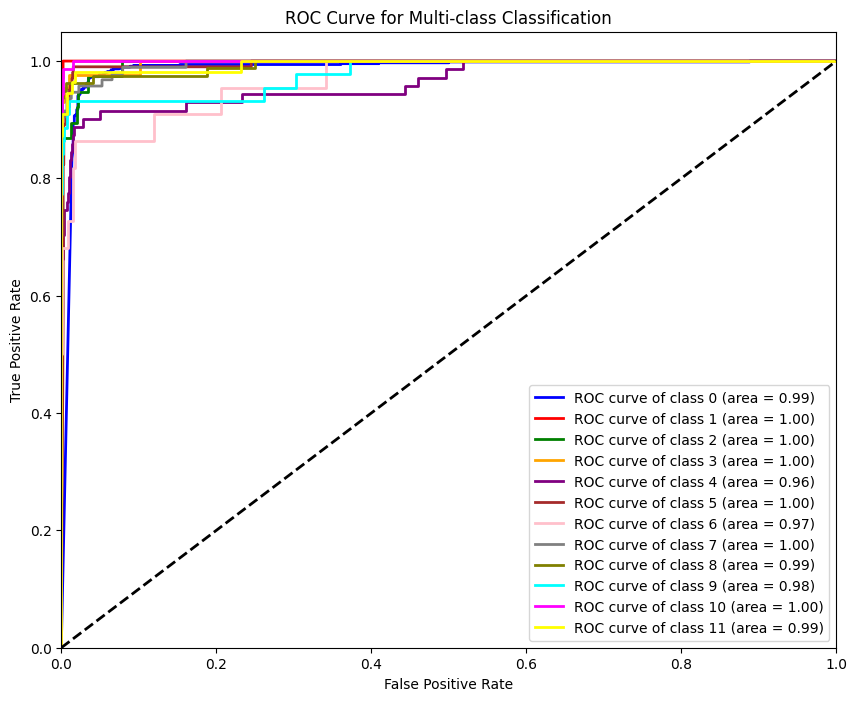

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Assuming you have your test_loader, model, and criterion defined
# test_loader: DataLoader object containing test data
# model: your trained model
# criterion: your loss function (if needed)

# Set model to evaluation mode
model.eval()

# Lists to store true labels and predicted probabilities
true_labels = []
predicted_probs = []

# Iterate through test data
with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.permute(1, 0, 2)
        outputs = model(videos)
        _, predicted = torch.max(outputs.data, 1)
        true_labels.extend(labels.cpu().numpy())
        predicted_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())


# Binarize the true labels
n_classes = len(np.unique(true_labels))
true_labels = label_binarize(true_labels, classes=range(n_classes))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(true_labels[:, i], np.array(predicted_probs)[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta', 'yellow']
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multi-class Classification')
plt.legend(loc="lower right")
plt.show()

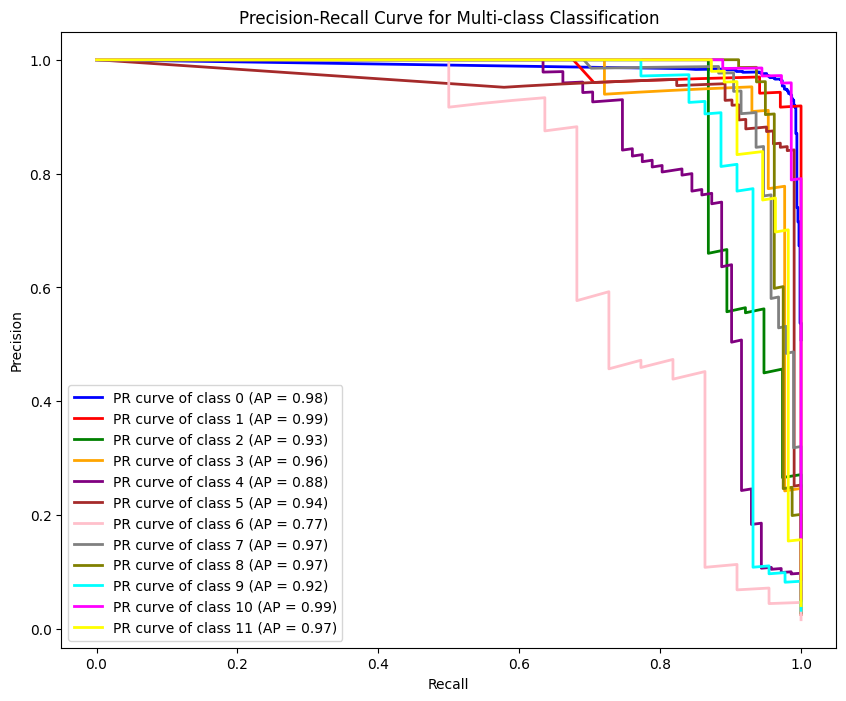

In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Assuming you have your test_loader, model, and criterion defined
# test_loader: DataLoader object containing test data
# model: your trained model
# criterion: your loss function (if needed)

# Set model to evaluation mode
model.eval()

# Lists to store true labels and predicted probabilities
true_labels = []
predicted_probs = []

# Iterate through test data
with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.permute(1, 0, 2)
        outputs = model(videos)
        _, predicted = torch.max(outputs.data, 1)
        true_labels.extend(labels.cpu().numpy())
        predicted_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())

# Binarize the true labels
n_classes = len(np.unique(true_labels))
true_labels = label_binarize(true_labels, classes=range(n_classes))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(true_labels[:, i], np.array(predicted_probs)[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# # ROC curve plotting (unchanged from previous code)

# ... (your ROC curve plotting code here)

# Compute Precision-Recall curve and Average Precision for each class
precision = dict()
recall = dict()
average_precision = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(true_labels[:, i], np.array(predicted_probs)[:, i])
    average_precision[i] = average_precision_score(true_labels[:, i], np.array(predicted_probs)[:, i])

# Plot Precision-Recall curves
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'magenta', 'yellow']
for i in range(n_classes):
    plt.plot(recall[i], precision[i], color=colors[i], lw=2,
           label='PR curve of class {0} (AP = {1:0.2f})'
           .format(i, average_precision[i]))

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Multi-class Classification')
plt.legend(loc="lower left")
plt.show()

In [22]:
inference_embeddings.shape, inference_labels.shape

(torch.Size([350, 150, 1024]), torch.Size([350]))

In [23]:
with torch.no_grad():
    correct = 0
    total = 0
    for videos, labels in inference_loader:
        videos = videos.permute(1, 0, 2)
        outputs = model(videos)
        _, predicted = torch.max(outputs.data, 1)
#         print('------------------------------------------------------------------')
#         print('Predicted: \t', predicted)
#         print('Actual: \t', labels)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f'Inference Accuracy of the model on the inference videos: {100 * correct / total}%')

Inference Accuracy of the model on the inference videos: 95.42857142857143%
